**Review Sentiment Analysis under Domain Shift**
- ARTI 404: Natural Language Processing - Section 9MA2 - Group 6 - Option 2: Review Sentiment Analysis.
- Ali Mohammed AlYousef (Team Leader) - 2230006252 - Data loading, cleaning, splits.
- Adam Ibrahim Alzaki - 2230003411 - Method 1 (TF-IDF + LR), Try it cell.
- Ahmed Murad Alshowaikhat - 2230005366 - Method 2 (MiniLM + LR), results.


- Experimental question: When trained on reviews from one domain, which method loses less macro F1 on the two unseen domains: TF-IDF with logistic regression, or pretrained sentence embeddings with logistic regression?

1. Setup

In [1]:
import importlib.util, subprocess, sys, os
if importlib.util.find_spec("sentence_transformers") is None:   # the only package Colab does not ship with
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)

import io, json, re, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, scipy, joblib, sentence_transformers, torch
from IPython.display import display
from scipy.stats import binomtest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

SEED = 42 # random_state of every random step (splits, samples); LR and the frozen encoder are deterministic
DOMAINS = ["Amazon", "Yelp", "IMDb"]
METHODS = ["TF-IDF + LR", "MiniLM + LR"]
LABELS = {0: "Negative", 1: "Positive"}
ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
TOKEN = r"(?u)\b\w[\w']*\b" # word pattern that keeps don't, isn't
DATA_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("data"), Path("results"), Path("figures"), Path("models")
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

def clean_text(text):
    for bad, good in {"\x85": "...", "\x96": "-", "\x97": "-"}.items():     # ellipsis, en dash, em dash
        text = text.replace(bad, good)
    return re.sub(r"\s+", " ", text).strip()

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"scipy {scipy.__version__} | sentence-transformers {sentence_transformers.__version__} | torch {torch.__version__}")

Python 3.12.13 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1 | sentence-transformers 6.1.0 | torch 2.14.1+cpu


2. Data

UCI Sentiment Labelled Sentences (CC BY 4.0): 1,000 sentences per domain (Amazon, Yelp, IMDb), 500 Positive / 500 Negative. Light cleaning only: Windows-1252 characters and extra spaces (every IMDb line ends with trailing spaces, so all 1,000 change). A lower-cased key finds duplicates.

In [2]:
FILES = {"Amazon": "amazon_cells_labelled.txt", "Yelp": "yelp_labelled.txt", "IMDb": "imdb_labelled.txt"}
if not all((DATA_DIR / f).exists() for f in FILES.values()):          # download once from UCI
    url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
    zf = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    for name in zf.namelist():
        if Path(name).name in FILES.values():
            (DATA_DIR / Path(name).name).write_bytes(zf.read(name))

def load_domain(domain):
    # Split on "\n" only: IMDb contains \x85, which str.splitlines() treats as a line break.
    lines = (DATA_DIR / FILES[domain]).read_text(encoding="utf-8").split("\n")
    df = pd.DataFrame([line.rsplit("\t", 1) for line in lines if line.strip()], columns=["raw_text", "label"])
    assert len(df) == 1000, f"{domain}: expected 1000 rows, got {len(df)}"
    return df.astype({"label": int}).assign(domain=domain)

data = pd.concat([load_domain(d) for d in DOMAINS], ignore_index=True)
data["text"] = data.raw_text.map(clean_text)
data["key"] = data.text.str.lower()
data["n_words"] = data.text.str.split().str.len()
data["row_id"] = np.arange(len(data))

changed = (data.text != data.raw_text).groupby(data.domain).sum().to_dict()
special = data.raw_text.str.contains("[\x85\x96\x97]").sum()
dup_rows = data.duplicated(["domain", "key"], keep=False).sum()               # rows whose text repeats in the same domain
conflicts = data.groupby(["domain", "key"]).label.nunique().gt(1).sum()     # duplicate groups with two labels
multi_domain = data.groupby("key").domain.nunique().gt(1).sum()             # texts found in more than one domain
print("Rows loaded:", len(data))
print("Sentences changed by cleaning:", changed, "| with Windows-1252 characters:", special)
print("Rows sharing their text with another row in the same domain:", dup_rows,
      "| duplicate groups with conflicting labels:", conflicts, "| texts in more than one domain:", multi_domain)
data.groupby("domain").head(2)[["domain", "text", "label"]]

Rows loaded: 3000
Sentences changed by cleaning: {'Amazon': 0, 'IMDb': 1000, 'Yelp': 0} | with Windows-1252 characters: 8
Rows sharing their text with another row in the same domain: 38 | duplicate groups with conflicting labels: 0 | texts in more than one domain: 1


,domain,text,label
0,Amazon,So there is no way for me to plug it in here in the US unless I go by a converter.,0
1,Amazon,"Good case, Excellent value.",1
1000,Yelp,Wow... Loved this place.,1
1001,Yelp,Crust is not good.,0
2000,IMDb,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",0
2001,IMDb,"Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.",0


In [3]:
summary = data.pivot_table(index="domain", columns="label", values="text", aggfunc="count").rename(columns=LABELS)
summary["Total"] = summary.sum(axis=1)
summary.loc["All"] = summary.sum()
length = data.groupby("domain").n_words.agg(["mean", "median", "max"])
length.loc["All"] = data.n_words.agg(["mean", "median", "max"])
length.columns = ["Mean words", "Median words", "Max words"]
summary = summary.join(length.round(1)).loc[DOMAINS + ["All"]]
summary.to_csv(RESULTS_DIR / "dataset_summary.csv")
summary

,Negative,Positive,Total,Mean words,Median words,Max words
domain,,,,,,
Amazon,500,500,1000,10.2,9.0,30.0
Yelp,500,500,1000,10.9,10.0,32.0
IMDb,500,500,1000,14.4,12.0,71.0
All,1500,1500,3000,11.8,10.0,71.0


Splits: stratified 70/15/15 train/dev/test inside each domain (seed 42), made on groups of identical sentences so a duplicate never sits in two splits. Models learn from the source train split and are tuned on the source dev split. Test sets are used once: in-domain = the source test split; cross-domain = both unseen domains, minus any sentence that is also in the source training split.

In [4]:
def make_splits(df, seed):
    split = pd.Series(index=df.index, dtype=object)
    for _, part in df.groupby("domain"):
        key_labels = part.groupby("key").label.first()                # one label per unique sentence
        train, rest = train_test_split(key_labels, test_size=0.30, stratify=key_labels, random_state=seed)
        dev, test = train_test_split(rest, test_size=0.50, stratify=rest, random_state=seed)
        names = {**dict.fromkeys(train.index, "train"), **dict.fromkeys(dev.index, "dev"), **dict.fromkeys(test.index, "test")}
        split.loc[part.index] = part.key.map(names)
    return split

data["split"] = make_splits(data, SEED)
print("Duplicate groups spread over more than one split:", data.groupby(["domain", "key"]).split.nunique().gt(1).sum())
split_table = data.pivot_table(index=["domain", "split"], columns="label", values="text", aggfunc="count").rename(columns=LABELS)
split_table["Total"] = split_table.sum(axis=1)
split_table.to_csv(RESULTS_DIR / "split_counts.csv")
split_table

Duplicate groups spread over more than one split: 0


label         Negative  Positive  Total
domain split                           
Amazon dev          76        76    152
       test         76        75    151
       train       348       349    697
IMDb   dev          76        76    152
       test         75        75    150
       train       349       349    698
Yelp   dev          75        75    150
       test         75        75    150
       train       350       350    700

3. Method 1: TF-IDF + Logistic Regression

TF-IDF vectors over word n-grams learned from the source training sentences, then logistic regression. Words never seen in training get no weight. Tuned on dev: n-gram range (1,1) or (1,2) and C in {0.01, 0.1, 1, 10, 100}, by macro F1 (ties keep the first, simpler setting).

In [5]:
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
TFIDF_GRID = [{"C": C, "ngram": ngram} for ngram in [(1, 1), (1, 2)] for C in C_GRID]   # list order = tie-break order

def build_tfidf(C, ngram):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=ngram, sublinear_tf=True, token_pattern=TOKEN)),
                     ("clf", LogisticRegression(C=C, max_iter=2000))])

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def tune(build, grid, X_train, y_train, X_dev, y_dev):
    best, best_f1 = None, -1
    for params in grid:
        model = build(**params).fit(X_train, y_train)
        f1 = macro_f1(y_dev, model.predict(X_dev))
        if f1 > best_f1:
            best, best_f1 = model, f1
    return best, best_f1

4. Method 2: Pretrained sentence embeddings + Logistic Regression

Each sentence goes through the frozen all-MiniLM-L6-v2 encoder (mean-pooled, normalised 384-d vector), then the same logistic regression, so only the text representation differs. Tuned on dev: C in {0.01, 0.1, 1, 10, 100}. The encoder never sees a label.

In [6]:
encoder = SentenceTransformer(ENCODER_NAME, device="cpu")          # pretrained weights, used frozen
EMB = encoder.encode(data.text.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
print("Embedding matrix:", EMB.shape)
EMB_GRID = [{"C": C} for C in C_GRID]

def build_emb(C):
    return LogisticRegression(C=C, max_iter=2000)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding matrix: (3000, 384)


5. Results

5.1 Main experiment - seed 42

In [7]:
def run_experiment(df, seed):
    df = df.assign(split=make_splits(df, seed))
    metrics, preds, tuning, tfidf_models = [], [], [], {}
    for source in DOMAINS:
        src = df[df.domain == source]
        train, dev = src[src.split == "train"], src[src.split == "dev"]
        tf, tf_f1 = tune(build_tfidf, TFIDF_GRID, train.text, train.label, dev.text, dev.label)
        emb, emb_f1 = tune(build_emb, EMB_GRID, EMB[train.row_id], train.label, EMB[dev.row_id], dev.label)
        tfidf_models[source] = tf
        tuning.append({"source": source, "tfidf_ngram": str(tf["tfidf"].ngram_range), "tfidf_C": tf["clf"].C,
                       "tfidf_dev_f1": tf_f1, "emb_C": emb.C, "emb_dev_f1": emb_f1})

        tests = {"in-domain": src[src.split == "test"]}
        for t in DOMAINS:
            if t != source:     # whole unseen domain, minus sentences that are in the source training split
                tests[t] = df[(df.domain == t) & ~df.key.isin(train.key)]
        tests["cross-domain"] = pd.concat([tests[t] for t in DOMAINS if t != source])
        for name, ts in tests.items():
            p_tf, p_emb = tf.predict(ts.text), emb.predict(EMB[ts.row_id])
            for method, p in zip(METHODS, (p_tf, p_emb)):
                metrics.append({"seed": seed, "source": source, "test_set": name, "method": method, "n": len(ts),
                                "accuracy": accuracy_score(ts.label, p), "macro_f1": macro_f1(ts.label, p)})
            if name != "cross-domain":          # skip the pooled set: its rows are already in the two per-target sets
                preds.append(ts[["row_id", "domain", "text", "label"]].assign(
                    source=source, test_set="in-domain" if name == "in-domain" else "cross-domain",
                    pred_tfidf=p_tf, pred_emb=p_emb,
                    p_pos_tfidf=tf.predict_proba(ts.text)[:, 1], p_pos_emb=emb.predict_proba(EMB[ts.row_id])[:, 1]))
    return pd.DataFrame(metrics), pd.concat(preds, ignore_index=True), pd.DataFrame(tuning), tfidf_models

metrics, predictions, tuning, TFIDF_MODELS = run_experiment(data, SEED)
metrics.to_csv(RESULTS_DIR / "metrics_seed42.csv", index=False)
predictions.to_csv(RESULTS_DIR / "predictions_seed42.csv", index=False)
tuning.to_csv(RESULTS_DIR / "dev_tuning_seed42.csv", index=False)
print("Settings selected on the source dev split:")
tuning.round(3)

Settings selected on the source dev split:


,source,tfidf_ngram,tfidf_C,tfidf_dev_f1,emb_C,emb_dev_f1
0,Amazon,"(1, 2)",100.0,0.802,10.0,0.901
1,Yelp,"(1, 1)",10.0,0.820,10.0,0.927
2,IMDb,"(1, 1)",10.0,0.780,10.0,0.921


In [8]:
# Test-set sizes (identical for both methods), then accuracy and macro F1 on every test set
COLS = ["in-domain"] + DOMAINS + ["cross-domain"]
display(metrics[metrics.method == METHODS[0]].pivot(index="source", columns="test_set", values="n").loc[DOMAINS, COLS])
full = metrics.pivot_table(index=["source", "test_set"], columns="method", values=["accuracy", "macro_f1"])
full = full.loc[[(s, t) for s in DOMAINS for t in COLS if (s, t) in full.index]].round(3)
full.to_csv(RESULTS_DIR / "results_full_seed42.csv")
full

test_set,in-domain,Amazon,Yelp,IMDb,cross-domain
source,,,,,
Amazon,151.0,NaN,1000.0,1000.0,2000.0
Yelp,150.0,1000.0,NaN,1000.0,2000.0
IMDb,150.0,999.0,1000.0,NaN,1999.0


accuracy                macro_f1            
method              MiniLM + LR TF-IDF + LR MiniLM + LR TF-IDF + LR
source test_set                                                    
Amazon in-domain          0.854       0.768       0.854       0.768
       Yelp               0.857       0.719       0.857       0.717
       IMDb               0.847       0.665       0.845       0.657
       cross-domain       0.852       0.692       0.852       0.687
Yelp   in-domain          0.860       0.813       0.860       0.813
       Amazon             0.846       0.745       0.845       0.745
       IMDb               0.854       0.678       0.852       0.676
       cross-domain       0.850       0.712       0.848       0.711
IMDb   in-domain          0.927       0.840       0.927       0.840
       Amazon             0.844       0.709       0.844       0.709
       Yelp               0.873       0.717       0.873       0.717
       cross-domain       0.858       0.713       0.858       0.713

In [9]:
def drop_table(m):
    t = m[m.test_set.isin(["in-domain", "cross-domain"])].pivot_table(
        index=["method", "source"], columns="test_set", values=["accuracy", "macro_f1"])
    out = pd.DataFrame({"In-domain acc": t[("accuracy", "in-domain")], "In-domain F1": t[("macro_f1", "in-domain")],
                        "Cross-domain acc": t[("accuracy", "cross-domain")], "Cross-domain F1": t[("macro_f1", "cross-domain")]})
    out["F1 drop"] = out["In-domain F1"] - out["Cross-domain F1"]
    means = out.groupby(level="method").mean()
    means.index = pd.MultiIndex.from_product([means.index, ["Mean of 3 runs"]])
    return pd.concat([out, means]).reindex([(mt, s) for mt in METHODS for s in DOMAINS + ["Mean of 3 runs"]])

drops = drop_table(metrics)
drops.round(3).to_csv(RESULTS_DIR / "drop_table_seed42.csv")
drops.round(3)

In-domain acc  In-domain F1  Cross-domain acc  Cross-domain F1  F1 drop
method                                                                                             
TF-IDF + LR Amazon                  0.768         0.768             0.692            0.687    0.081
            Yelp                    0.813         0.813             0.712            0.711    0.102
            IMDb                    0.840         0.840             0.713            0.713    0.127
            Mean of 3 runs          0.807         0.807             0.705            0.704    0.103
MiniLM + LR Amazon                  0.854         0.854             0.852            0.852    0.002
            Yelp                    0.860         0.860             0.850            0.848    0.012
            IMDb                    0.927         0.927             0.858            0.858    0.068
            Mean of 3 runs          0.880         0.880             0.853            0.853    0.027

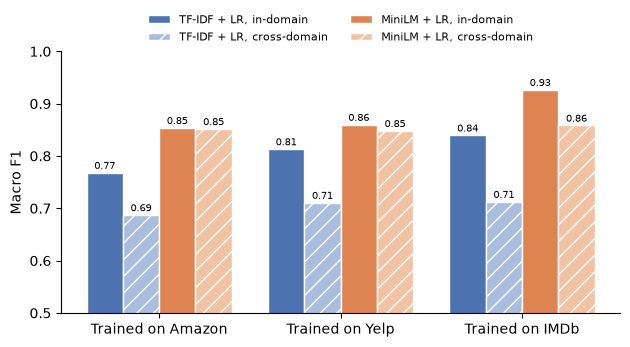

In [10]:
# Fig. 2 of the report: in-domain vs cross-domain macro F1 per source domain
fig, ax = plt.subplots(figsize=(6.4, 3.6))
bars = [("TF-IDF + LR", "In-domain F1", "#4C72B0", ""), ("TF-IDF + LR", "Cross-domain F1", "#A9BEDE", "//"),
        ("MiniLM + LR", "In-domain F1", "#DD8452", ""), ("MiniLM + LR", "Cross-domain F1", "#F2C3A3", "//")]
x = np.arange(len(DOMAINS))
for k, (method, col, color, hatch) in enumerate(bars):
    b = ax.bar(x + (k - 1.5) * 0.2, [drops.loc[(method, s), col] for s in DOMAINS], 0.2, color=color, hatch=hatch,
               edgecolor="white", label=f"{method}, {col.split()[0].lower()}")
    ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x, [f"Trained on {s}" for s in DOMAINS])
ax.set_ylabel("Macro F1"); ax.set_ylim(0.5, 1.0); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.18))
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_in_vs_cross_f1.png", dpi=200); plt.show()

5.2 Why does the drop happen? Unseen vocabulary

In [11]:
def words(texts):
    return [w for t in texts for w in re.findall(TOKEN, t.lower())]

VOCAB = {s: set(words(data[(data.domain == s) & (data.split == "train")].text)) for s in DOMAINS}   # source training words

rows = []
for s in DOMAINS:
    for t in DOMAINS:
        if t != s:
            f1 = metrics[(metrics.source == s) & (metrics.test_set == t)].set_index("method").macro_f1
            rows.append({"source": s, "target": t, "unseen word tokens": np.mean([w not in VOCAB[s] for w in words(data[data.domain == t].text)]),
                         "TF-IDF F1": f1["TF-IDF + LR"], "MiniLM F1": f1["MiniLM + LR"]})
oov = pd.DataFrame(rows)
oov.round(3).to_csv(RESULTS_DIR / "oov_vs_f1.csv", index=False)
print("Correlation between unseen-token rate and F1 (6 pairs):",
      {m: round(float(oov["unseen word tokens"].corr(oov[m])), 2) for m in ["TF-IDF F1", "MiniLM F1"]})
oov.round(3)

Correlation between unseen-token rate and F1 (6 pairs): {'TF-IDF F1': -0.75, 'MiniLM F1': -0.25}


,source,target,unseen word tokens,TF-IDF F1,MiniLM F1
0,Amazon,Yelp,0.262,0.717,0.857
1,Amazon,IMDb,0.318,0.657,0.845
2,Yelp,Amazon,0.265,0.745,0.845
3,Yelp,IMDb,0.308,0.676,0.852
4,IMDb,Amazon,0.230,0.709,0.844
5,IMDb,Yelp,0.247,0.717,0.873


What each source domain learns: top TF-IDF words

In [12]:
rows = {}
for s, model in TFIDF_MODELS.items():
    names = model["tfidf"].get_feature_names_out()
    order = np.argsort(model["clf"].coef_[0])          # ascending: first 8 = most Negative, last 8 = most Positive
    rows[s] = {"most Positive": ", ".join(names[order[::-1][:8]]), "most Negative": ", ".join(names[order[:8]])}
top_words = pd.DataFrame(rows).T.rename_axis("source")
top_words.to_csv(RESULTS_DIR / "top_tfidf_words.csv")
top_words

,most Positive,most Negative
source,,
Amazon,"great, works, good, nice, excellent, well, very, and","not, poor, bad, disappointed, the battery, doesn't, horrible, worst"
Yelp,"great, good, delicious, amazing, love, awesome, fantastic, fun","not, at, wasn't, never, bad, bland, don't, terrible"
IMDb,"liked, great, funny, beautiful, wonderful, a, right, good","bad, script, even, awful, cheap, plot, worst, terrible"


Where the errors fall: class balance, sentence length and negation

In [13]:
cross = predictions[predictions.test_set == "cross-domain"].copy()
cross["tf_ok"], cross["emb_ok"] = cross.pred_tfidf == cross.label, cross.pred_emb == cross.label
cross["length"] = pd.cut(cross.text.str.split().str.len(), [0, 6, 12, 200], labels=["1-6 words", "7-12 words", "13+ words"])
cross["negation"] = np.where(cross.text.str.lower().str.contains(r"\b(?:not|no|never|nothing|nor|neither|without)\b|n't"),
                             "with negation", "no negation")

recall = pd.DataFrame({m: {"Recall Positive": recall_score(cross.label, cross[c], pos_label=1),
                           "Recall Negative": recall_score(cross.label, cross[c], pos_label=0)}
                       for m, c in zip(METHODS, ["pred_tfidf", "pred_emb"])}).T.round(3)
recall.to_csv(RESULTS_DIR / "cross_recall_per_class.csv")
display(recall)
for col in ["length", "negation"]:
    g = cross.groupby(col, observed=True)
    table = pd.DataFrame({"n": g.size(), "TF-IDF acc": g.tf_ok.mean(), "MiniLM acc": g.emb_ok.mean()}).round(3)
    table.to_csv(RESULTS_DIR / f"cross_acc_by_{col}.csv")
    display(table)

,Recall Positive,Recall Negative
TF-IDF + LR,0.657,0.754
MiniLM + LR,0.807,0.900


,n,TF-IDF acc,MiniLM acc
length,,,
1-6 words,1751,0.777,0.903
7-12 words,1980,0.707,0.852
13+ words,2268,0.649,0.817


,n,TF-IDF acc,MiniLM acc
negation,,,
no negation,4639,0.706,0.867
with negation,1360,0.704,0.809


McNemar's test - is the difference massive? 

In [14]:
rows = []
for s in DOMAINS:
    d = cross[cross.source == s]
    only_tf, only_emb = int((d.tf_ok & ~d.emb_ok).sum()), int((d.emb_ok & ~d.tf_ok).sum())
    p = binomtest(only_tf, only_tf + only_emb, 0.5).pvalue    # exact McNemar = two-sided binomial test on the disagreements
    rows.append({"source": s, "n": len(d), "only TF-IDF right": only_tf, "only MiniLM right": only_emb, "p-value": f"{p:.1e}"})
mcnemar = pd.DataFrame(rows).set_index("source")
mcnemar.to_csv(RESULTS_DIR / "mcnemar_cross_domain.csv")
mcnemar

,n,only TF-IDF right,only MiniLM right,p-value
source,,,,
Amazon,2000,123,443,2.2e-43
Yelp,2000,121,398,1.7e-35
IMDb,1999,138,429,1.1e-35


5.3 Robustness check - five different splits

In [15]:
SEEDS = [SEED, 7, 123, 2024, 31337]
all_runs = pd.concat([metrics] + [run_experiment(data, s)[0] for s in SEEDS[1:]], ignore_index=True)   # reuse the main run
all_runs.to_csv(RESULTS_DIR / "metrics_5_seeds.csv", index=False)

rows = []
for s in SEEDS:
    seed_table = drop_table(all_runs[all_runs.seed == s])
    for m in METHODS:
        r = seed_table.loc[(m, "Mean of 3 runs")]           # mean over the 3 source domains
        rows.append({"seed": s, "method": m, "in_f1": r["In-domain F1"], "cross_f1": r["Cross-domain F1"], "drop": r["F1 drop"]})
per_seed = pd.DataFrame(rows)
robust = per_seed.groupby("method")[["in_f1", "cross_f1", "drop"]].agg(["mean", "std"]).round(3)
robust.to_csv(RESULTS_DIR / "robustness_5_seeds.csv")
drop = per_seed.pivot(index="seed", columns="method", values="drop")
print(f"Seeds where MiniLM + LR has the smaller mean drop: {(drop['MiniLM + LR'] < drop['TF-IDF + LR']).sum()} of {len(SEEDS)}")
robust

Seeds where MiniLM + LR has the smaller mean drop: 5 of 5


in_f1        cross_f1          drop       
              mean    std     mean    std   mean    std
method                                                 
MiniLM + LR  0.878  0.005    0.855  0.006  0.023  0.007
TF-IDF + LR  0.800  0.012    0.702  0.006  0.097  0.014

5.4 Error analysis

In [16]:
cross["pattern"] = np.select([~cross.tf_ok & ~cross.emb_ok, ~cross.tf_ok, ~cross.emb_ok],
                             ["both wrong", "only TF-IDF wrong", "only MiniLM wrong"], "both right")
print(pd.crosstab(cross.source, cross.pattern, margins=True))

def show(df):
    return df[["source", "domain", "text", "label", "p_pos_tfidf", "p_pos_emb"]].rename(columns={"domain": "target"}).round(2)

for pattern in ["only TF-IDF wrong", "only MiniLM wrong", "both wrong"]:
    print(f"\n{pattern}:")
    display(show(cross[cross.pattern == pattern].sample(6, random_state=SEED)))

pattern  both right  both wrong  only MiniLM wrong  only TF-IDF wrong   All
source                                                                     
Amazon         1261         173                123                443  2000
IMDb           1287         145                138                429  1999
Yelp           1302         179                121                398  2000
All            3850         497                382               1270  5999

only TF-IDF wrong:


,source,target,text,label,p_pos_tfidf,p_pos_emb
6178,IMDb,Yelp,The Han Nan Chicken was also very tasty.,1,0.20,0.89
5888,IMDb,Yelp,Wow very spicy but delicious.,1,0.22,0.63
2084,Amazon,IMDb,"Kathy Bates is wonderful in her characters subtle desperation and escapism; a variation on her character in ""At Play...",1,0.23,0.51
5111,IMDb,Amazon,I'm happy about this purchase- good quality and low price.,1,0.44,1.00
4089,Yelp,IMDb,10/10,1,0.25,0.86
4047,Yelp,IMDb,"In fact, I liked it better than Interview With a Vampire and I liked this Lestat (Stuart Townsend) better than Cruis...",1,0.45,0.70



only MiniLM wrong:


,source,target,text,label,p_pos_tfidf,p_pos_emb
5041,IMDb,Amazon,Linked to my phone without effort.,1,0.57,0.02
4508,IMDb,Amazon,I even dropped this phone into a stream and it was submerged for 15 seconds and it still works great!,1,0.89,0.16
3758,Yelp,IMDb,If only someone involved with it knew how to string together narrative!,0,0.13,0.78
5572,IMDb,Yelp,Service was fine and the waitress was friendly.,1,0.52,0.47
979,Amazon,Yelp,The service here is fair at best.,0,0.47,0.95
6333,IMDb,Yelp,I ordered Albondigas soup - which was just warm - and tasted like tomato soup with frozen meatballs.,0,0.46,0.55



both wrong:


,source,target,text,label,p_pos_tfidf,p_pos_emb
6189,IMDb,Yelp,Never had anything to complain about here.,1,0.39,0.02
1203,Amazon,IMDb,It's hard not to fall head-over-heels in love with that girl.,1,0.16,0.24
3147,Yelp,Amazon,Used and dirty.,0,0.50,0.58
2354,Yelp,Amazon,This phone is pretty sturdy and I've never had any large problems with it.,1,0.39,0.05
3200,Yelp,Amazon,The pairing of the two devices was so easy it barely took a couple minutes before I started making calls with the vo...,1,0.06,0.41
5270,IMDb,Amazon,Plan on ordering from them again and again.,1,0.28,0.25


In [17]:
ANALYSED = [("IMDb", "The Han Nan Chicken was also very tasty."),                       # (source, sentence)
            ("IMDb", "I'm happy about this purchase- good quality and low price."),
            ("Amazon", "The service here is fair at best."),
            ("Yelp", "If only someone involved with it knew how to string together narrative!"),
            ("IMDb", "Linked to my phone without effort."),
            ("IMDb", "Never had anything to complain about here.")]
analysed = pd.concat([cross[(cross.source == s) & (cross.text == t)] for s, t in ANALYSED])
analysed.index = [f"E{i + 1}" for i in range(len(analysed))]
analysed[list(predictions.columns) + ["pattern"]].to_csv(RESULTS_DIR / "analysed_errors.csv", index=False)

def explain_tfidf(text, source, top=6):
    vectorizer, clf = TFIDF_MODELS[source]["tfidf"], TFIDF_MODELS[source]["clf"]
    x = vectorizer.transform([text]).toarray()[0]                              # tf-idf of every n-gram (0 if absent)
    names = vectorizer.get_feature_names_out()
    pushes = [(names[i], x[i] * clf.coef_[0][i]) for i in np.nonzero(x)[0]]   # contribution = tf-idf x weight, + = Positive
    pushes.sort(key=lambda p: abs(p[1]), reverse=True)
    unseen = [w for w in re.findall(TOKEN, text.lower()) if w not in VOCAB[source]]
    return pd.Series({"unseen words": ", ".join(unseen) or "-",
                      "strongest known features (+ = Positive)": ", ".join(f"{w} ({c:+.2f})" for w, c in pushes[:top])})

display(show(analysed))
pd.DataFrame([explain_tfidf(r.text, r.source) for r in analysed.itertuples()], index=analysed.index)

,source,target,text,label,p_pos_tfidf,p_pos_emb
E1,IMDb,Yelp,The Han Nan Chicken was also very tasty.,1,0.20,0.89
E2,IMDb,Amazon,I'm happy about this purchase- good quality and low price.,1,0.44,1.00
E3,Amazon,Yelp,The service here is fair at best.,0,0.47,0.95
E4,Yelp,IMDb,If only someone involved with it knew how to string together narrative!,0,0.13,0.78
E5,IMDb,Amazon,Linked to my phone without effort.,1,0.57,0.02
E6,IMDb,Yelp,Never had anything to complain about here.,1,0.39,0.02


,unseen words,strongest known features (+ = Positive)
E1,"han, nan, chicken, tasty","very (-0.69), was (-0.33), the (-0.18), also (+0.03)"
E2,"happy, purchase, price","good (+0.95), i'm (-0.60), low (-0.52), and (+0.45), about (-0.15), quality (-0.15)"
E3,fair,"best (+1.73), at (-0.99), is (+0.69), the service (-0.58), the (-0.48), here (+0.25)"
E4,"involved, knew, string, narrative","if (-0.78), someone (-0.62), only (-0.37), with (+0.32), together (+0.28), how (-0.28)"
E5,"linked, phone","without (+0.14), my (+0.13), effort (+0.12), to (+0.07)"
E6,complain,"about (-0.16), here (-0.15), had (+0.11), never (-0.07), to (+0.07), anything (-0.05)"


Answer: pretrained sentence embeddings + logistic regression lose much less macro F1 when the domain changes.
- Seed 42, mean over the 3 sources: TF-IDF drops 0.103 (0.807 -> 0.704), MiniLM 0.027 (0.880 -> 0.853). MiniLM drops less for every source.
- Five seeds: mean drop 0.097 +/- 0.014 vs 0.023 +/- 0.007; MiniLM drops less in 5 of 5.
- Why: 23-32% of target-domain word tokens never occur in the source training data. TF-IDF cannot use them; the pretrained encoder maps them to familiar meanings.

6. Try it with selected model

In [18]:
train_all, dev_all, test_all = (data[data.split == s] for s in ("train", "dev", "test"))
overlap = test_all.key.isin(train_all.key)            # a sentence can appear in two domains
print("Combined test sentences removed because they also appear in combined training data:", overlap.sum())
test_all = test_all[~overlap]

tfidf_final, tfidf_dev_f1 = tune(build_tfidf, TFIDF_GRID, train_all.text, train_all.label, dev_all.text, dev_all.label)
emb_final, emb_dev_f1 = tune(build_emb, EMB_GRID, EMB[train_all.row_id], train_all.label, EMB[dev_all.row_id], dev_all.label)
dev_f1 = {"TF-IDF + LR": tfidf_dev_f1, "MiniLM + LR": emb_dev_f1}
test_pred = {"TF-IDF + LR": tfidf_final.predict(test_all.text), "MiniLM + LR": emb_final.predict(EMB[test_all.row_id])}
SELECTED = max(dev_f1, key=dev_f1.get)                 # higher dev macro F1 (a tie keeps TF-IDF)

final_table = pd.DataFrame([{"method": m, "dev macro F1": dev_f1[m], "test n": len(test_all),
                             "test accuracy": accuracy_score(test_all.label, test_pred[m]),
                             "test macro F1": macro_f1(test_all.label, test_pred[m])} for m in METHODS]).set_index("method").round(3)
final_table.to_csv(RESULTS_DIR / "combined_model_results.csv")
joblib.dump(tfidf_final, MODEL_DIR / "tfidf_lr.joblib")
joblib.dump(emb_final, MODEL_DIR / "minilm_lr.joblib")
(MODEL_DIR / "selected_model.json").write_text(json.dumps({"selected": SELECTED, "encoder": ENCODER_NAME}, indent=2))
print("Selected model:", SELECTED)
final_table

Combined test sentences removed because they also appear in combined training data: 1
Selected model: MiniLM + LR


,dev macro F1,test n,test accuracy,test macro F1
method,,,,
TF-IDF + LR,0.830,450,0.809,0.809
MiniLM + LR,0.899,450,0.891,0.891


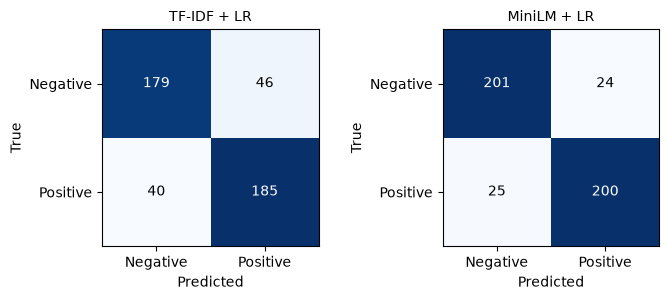

In [19]:
# Fig. 1 of the report: confusion matrices of both combined models on the combined test split
fig, axes = plt.subplots(1, 2, figsize=(7, 3.1))
for ax, m in zip(axes, METHODS):
    cm = confusion_matrix(test_all.label, test_pred[m], labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Negative", "Positive"]); ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(m, fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_confusion_combined.png", dpi=200); plt.show()

In [20]:
assert (MODEL_DIR / "tfidf_lr.joblib").exists(), "Saved models not found in models/. Run Section 5.6 once to create them."
tfidf_lr, minilm_lr = joblib.load(MODEL_DIR / "tfidf_lr.joblib"), joblib.load(MODEL_DIR / "minilm_lr.joblib")
SELECTED = json.loads((MODEL_DIR / "selected_model.json").read_text())["selected"]
OTHER = [m for m in METHODS if m != SELECTED][0]
if "encoder" not in globals():                         # loading pretrained weights is not retraining
    encoder = SentenceTransformer(ENCODER_NAME, device="cpu")

def predict_sentiment(text, method):
    text = clean_text(str(text))
    if method == "TF-IDF + LR":
        p_pos = tfidf_lr.predict_proba([text])[0, 1]
    else:
        p_pos = minilm_lr.predict_proba(encoder.encode([text], normalize_embeddings=True, show_progress_bar=False))[0, 1]
    return ("Positive" if p_pos >= 0.5 else "Negative"), float(max(p_pos, 1 - p_pos))

def show_prediction(text):
    if text is None or not str(text).strip():
        print("Please type a review, for example: 'The food was excellent.'")
        return
    print(f"Review     : {text}")
    for tag, method in [("Prediction", SELECTED), ("Comparison", OTHER)]:
        label, conf = predict_sentiment(text, method)
        note = " - selected model" if method == SELECTED else ""
        print(f"{tag} : {label}  (confidence {conf:.0%}, {method}{note})")

In [21]:
# TRY IT: edit the text between the quotes and run this cell
REVIEW = "The waiter was friendly and the food came quickly."
show_prediction(REVIEW)

Review     : The waiter was friendly and the food came quickly.
Prediction : Positive  (confidence 81%, MiniLM + LR - selected model)
Comparison : Positive  (confidence 91%, TF-IDF + LR)


In [22]:
# More examples, including empty input
for example in ["The battery died after two days.", "The food was not good.", "   ", "Not bad at all, I would buy it again."]:
    show_prediction(example); print()

Review     : The battery died after two days.
Prediction : Negative  (confidence 96%, MiniLM + LR - selected model)
Comparison : Negative  (confidence 100%, TF-IDF + LR)

Review     : The food was not good.
Prediction : Negative  (confidence 100%, MiniLM + LR - selected model)
Comparison : Negative  (confidence 99%, TF-IDF + LR)

Please type a review, for example: 'The food was excellent.'

Review     : Not bad at all, I would buy it again.
Prediction : Positive  (confidence 68%, MiniLM + LR - selected model)
Comparison : Negative  (confidence 100%, TF-IDF + LR)



Examples. they are not part of any test score:

In [23]:
ORIGINAL_EXAMPLES = [  
    ("Ali Mohammed AlYousef",    "The charger stopped working after one week.",                     "Negative"),
    ("Ali Mohammed AlYousef",    "Delivery was quick and the case fits my phone perfectly.",        "Positive"),
    ("Adam Ibrahim Alzaki",      "The shawarma was cold and the fries were soggy.",                 "Negative"),
    ("Adam Ibrahim Alzaki",      "I was not disappointed at all, the staff were lovely.",           "Positive"),
    ("Ahmed Murad Alshowaikhat", "The ending felt rushed and the jokes never landed.",              "Negative"),
    ("Ahmed Murad Alshowaikhat", "A slow start, but the last hour kept me on the edge of my seat.", "Positive"),
]
orig = pd.DataFrame(ORIGINAL_EXAMPLES, columns=["member", "sentence", "true label"])
for m in METHODS:
    orig[m] = [predict_sentiment(s, m)[0] for s in orig.sentence]
orig.to_csv(RESULTS_DIR / "original_examples.csv", index=False)
orig

,member,sentence,true label,TF-IDF + LR,MiniLM + LR
0,Ali Mohammed AlYousef,The charger stopped working after one week.,Negative,Positive,Negative
1,Ali Mohammed AlYousef,Delivery was quick and the case fits my phone perfectly.,Positive,Positive,Positive
2,Adam Ibrahim Alzaki,The shawarma was cold and the fries were soggy.,Negative,Negative,Negative
3,Adam Ibrahim Alzaki,"I was not disappointed at all, the staff were lovely.",Positive,Negative,Positive
4,Ahmed Murad Alshowaikhat,The ending felt rushed and the jokes never landed.,Negative,Negative,Negative
5,Ahmed Murad Alshowaikhat,"A slow start, but the last hour kept me on the edge of my seat.",Positive,Negative,Negative
